In [1]:
from lib.opt_types import *
from lib.utils import *
from lib.part_one import f, x_zero

# Stochastic gradient methods - 35 Points


In this part, you will implement stochastic gradient methods and compare their convergence on the logistic regression problem using the 3,376-shot Golden State Warriors subset from Part 2. You will then compare uniform and importance sampling on a separate test problem.

We write the regularized logistic regression objective introduced in [Part 2, equation (3)](Part%202%20-%20First%20order%20methods.ipynb#eq-binary-objective) in finite-sum form:

<a id="eq-objective"></a>

$$
\tag{6}
f(\mathbf{x}) = \frac{1}{n}\sum_{i=1}^n\bigg\{\underbrace{\log(1 + \exp(- b_i \mathbf{a}_i^T\mathbf{x})) + \frac{\mu}{2}\|\mathbf{x}\|^2}_{f_i(\mathbf{x})}\bigg\},
$$

We suppress the dependence on $\mu$ in the notation. The component gradients are

$$
\nabla f_i(\mathbf{x}) = -b_i \sigma(-b_i \cdot \mathbf{a}_i^T\mathbf{x})\mathbf{a}_i + \mu \mathbf{x}.
$$

The `Function` type provides access to the individual terms through the following attributes:

- To access the gradient of the `j`-th term at a point `x` you can write `f.i_grad(j, x)`.
- The number of terms $n$ is stored in the attribute `f.n`. 

Consider the following stochastic gradient update: At the iteration $k$, pick $i_k\in\{1, \ldots, n\}$ uniformly at random and define

<a id="eq-sgd"></a>

$$
\mathbf{x}^{k+1} :=  \mathbf{x}^k - \alpha_k\nabla{f}_{i_k}(\mathbf{x}^k).\tag{7}
$$

__(a)__ (2 points) Show that $\nabla f_{i_k}(\mathbf{x})$ is an unbiased estimator of $\nabla f(\mathbf{x})$. Explain why $\nabla f_{i_k}$ is Lipschitz continuous with the bound $L(f_{i_k}) = \|\mathbf{a}_{i_k}\|^2+ \mu $. 

__Hint__: Recall how we computed $L$ in Problem 1. In the following, we will set $L_{\max} = \max_{i\in\{1, \ldots, n\}}L(f_i)$.

Proof of unbiasedness

$$\mathbb{E}_{i_k} [\nabla f_{i_k}(\mathbf{x})] = \sum_{i=1}^{n} P(i_k = i) \nabla f_i(\mathbf{x}) = \sum_{i=1}^{n} \frac{1}{n} \nabla f_i(\mathbf{x}) = \frac{1}{n} \sum_{i=1}^{n} \nabla f_i(\mathbf{x}) = \nabla f(\mathbf{x})$$

Proof of Lipschitz continuity of $\nabla f_i$ and bound on $L_i$.

Let $A$ have rows $\mathbf a_i^\top$. From class, the average binary logistic loss is $L_0$-smooth with
$$
L_0=\frac14\|A^\top A\|_2
$$
(lecture 3, slide 34/41). The regularizer adds $\mu I$ to the Hessian, since
$$
\nabla^2\left(\frac{\mu}{2}\|\mathbf x\|^2\right)=\mu I.
$$
Hence
$$
L=\frac14\|A^\top A\|_2+\mu.
$$

for a single regularized component $f_i$, we apply the class result with the single-row matrix $A=\mathbf a_i^\top$. Since
$$
\|\mathbf a_i\mathbf a_i^\top\|_2=\|\mathbf a_i\|^2,
$$
we obtain
$$
\|\nabla^2 f_i(\mathbf x)\|_2
\le \frac14\|\mathbf a_i\|^2+\mu
\le L(f_i):=\|\mathbf a_i\|^2+\mu.
$$
Therefore, every sampled gradient satisfies
$$
\|\nabla f_{i_k}(\mathbf x)-\nabla f_{i_k}(\mathbf y)\|
\le L(f_{i_k})\|\mathbf x-\mathbf y\|.
$$

__(b)__ (2 points) 
Implement the [SGD update (7)](#eq-sgd) for [objective (6)](#eq-objective) by completing the following cells with $\alpha_k =\frac{0.01}{k}$, starting the counter at $k=1$.

**Hint**: For some `N`, the function `np.random.choice(N)` generates a random integer in $\{0, \dots, N-1 \}$.


In [2]:
@dataclass
class SGD_state(OptState):
    x_k: Vector
    k: int

In [3]:
def SGD_update(f, state):
    x_k, k = state
    i_k = np.random.randint(f.n) 
    alpha = 0.01 / k 
    next_x_k = x_k - alpha * f.i_grad(i_k, x_k)  
    return SGD_state(next_x_k, k+1)


def SGD_initialize(f, x_zero):
    return SGD_state(x_zero, 1)

In [4]:
SGD = OptAlgorithm(name="SGD", init_state=SGD_initialize, state_update=SGD_update)

__(c)__ (6 points) 
The stochastic average gradient method (`SAG`) stores the most recently computed gradient of each component and uses their average in the update:

<a id="eq-sag"></a>

$$
\tag{8}
\begin{cases}
\text{pick } i_k\in\{1, \ldots, n\} \text{ uniformly at random}\\
\mathbf{x}^{k+1} := \mathbf{x}^k - \frac{\alpha_k}{n}\sum_{i=1}^n\mathbf{v}_i^k,
\end{cases}
$$

where 

$$
\mathbf{v}_i^k =
\begin{cases}
\nabla f_i(\mathbf{x}^k) &\text{if}\, i = i_k,\\
\mathbf{v}_i^{k-1} &\text{otherwise}.
\end{cases}
$$

Implement the [SAG update (8)](#eq-sag) for [objective (6)](#eq-objective) by completing the following cells with $\alpha_k=\frac{0.01}{L_{\max}}$, initializing all stored gradients to zero. You can access $L_{\max}$ through `f.L_max`.

In [5]:
@dataclass
class SAG_state(OptState):
    x_k: Vector
    v_k: List[Vector]
    alpha_k: float

In [6]:
def SAG_update(f, state):
    x_k, v_k, alpha_k = state
    i_k = np.random.randint(f.n)

    v_k[i_k] = f.i_grad(i_k, x_k)
    
    # for i in range(f.n):
    #     if i == i_k:
    #         v_k[i] = f.i_grad(i, x_k)
    #     else:
    #         v_k[i] = v_k[i]  

    next_x_k = x_k - alpha_k * v_k.mean(axis=0)  # averages over rows -> v_k in R^{n x p}
    return SAG_state(x_k=next_x_k, v_k=v_k, alpha_k=alpha_k)


def SAG_initialize(f, x_zero):
    v_k = np.zeros((f.n, x_zero.shape[0]))
    alpha_k = 0.01 / f.L_max
    return SAG_state(x_k=x_zero, v_k=v_k, alpha_k=alpha_k)

In [7]:
SAG = OptAlgorithm(name="SAG", init_state=SAG_initialize, state_update=SAG_update)

SGD    :   0%|          | 0/500000 [00:00<?, ?it/s]

SGD    :   0%|          | 1564/500000 [00:00<00:31, 15632.64it/s]

SGD    :   1%|          | 3301/500000 [00:00<00:29, 16652.77it/s]

SGD    :   1%|          | 5108/500000 [00:00<00:28, 17299.72it/s]

SGD    :   1%|▏         | 6959/500000 [00:00<00:27, 17774.86it/s]

SGD    :   2%|▏         | 8831/500000 [00:00<00:27, 18111.93it/s]

... (680 outputs left out)

SAG    :  99%|█████████▉| 497056/500000 [00:43<00:00, 11555.35it/s]

SAG    : 100%|█████████▉| 498212/500000 [00:43<00:00, 11492.61it/s]

SAG    : 100%|█████████▉| 499374/500000 [00:43<00:00, 11528.28it/s]

SAG    : 100%|██████████| 500000/500000 [00:43<00:00, 11466.70it/s]

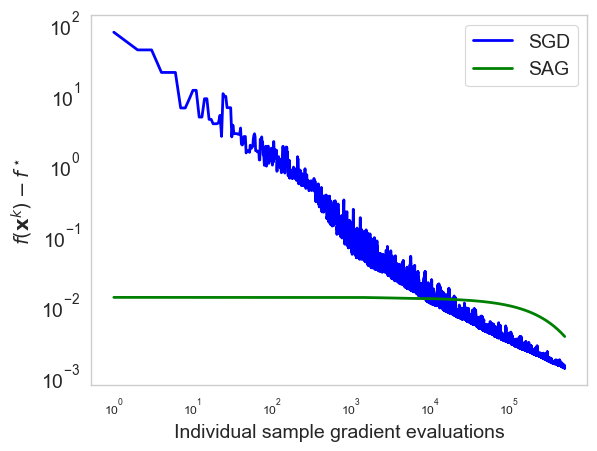

In [8]:
plot_epochs([SGD, SAG], f, x_zero, 500000, x_axis="gradient_evaluations")

__(d)__ (6 points) 
We can improve the convergence rate of SGD by periodically computing the full gradient. `SVRG` uses the following variance reduction scheme:

$$
\begin{cases}
\text{if } k = 0 \text{ mod } q:\\
\quad \mathbf{z} = \mathbf{x}^k\\
\quad \tilde{\mathbf{v}} = \nabla f(\mathbf{x}^k)\\
\text{Pick } i_k\in \{1, \ldots, n\} \text{ uniformly at random}\\
\mathbf{d}^k = \nabla f_{i_k}({\mathbf{x}}^k) - \nabla f_{i_k}(\mathbf{z}) + \tilde{\mathbf{v}}\\
{\mathbf{x}}^{k+1} := {\mathbf{x}}^k - \gamma\mathbf{d}^k\\
\end{cases}
$$

Implement `SVRG` by completing the following cells with $\gamma = 1/L_{\max}$ and $q = 100$.

In [9]:
@dataclass
class SVRG_state(OptState):
    x_k: Vector 
    z: Vector
    tilde_v: Vector
    q: int
    gamma: float
    k: int

In [10]:
def SVRG_update(f, state):
    x_k, z, tilde_v, q, gamma, k = state

    if k % q == 0:
        z = x_k
        tilde_v = f.grad(x_k)

    i_k = np.random.randint(f.n)
    d_k = f.i_grad(i_k, x_k) - f.i_grad(i_k, z) + tilde_v
    next_x_k = x_k - gamma * d_k

    return SVRG_state(
        x_k=next_x_k,
        z=z,
        tilde_v=tilde_v,
        q=q,
        gamma=gamma,
        k=k + 1,
    )


def SVRG_initialize(f, x_zero):
    return SVRG_state(
        x_k=x_zero,
        z=x_zero,
        tilde_v=np.zeros_like(x_zero),
        q=100,
        gamma=1.0 / f.L_max,
        k=0,
    )

In [11]:
SVRG = OptAlgorithm(name="SVRG", init_state=SVRG_initialize, state_update=SVRG_update)

__(e)__ (6 points) Another variance reduction method is `Spider`. The scheme can be described as follows:

$$
\begin{cases}
\text{if } k = 0 \text{ mod } q:\\
\quad {\mathbf{v}}^k = \nabla f({\mathbf{x}}^k)\\
\text{if } k \neq 0 \text{ mod } q:\\
\quad \text{Pick } i_k\in \{1, \ldots, n\} \text{ uniformly at random}\\
\quad {\mathbf{v}}^k = \nabla f_{i_k}({\mathbf{x}}^k) - \nabla f_{i_k}({\mathbf{x}}^{k-1}) + {\mathbf{v}}^{k-1}\\
\eta := \min \big(\frac{1}{\left \| {\mathbf{v}}^{k} \right \|_2}, \frac{1}{\epsilon}\big)\\
{\mathbf{x}}^{k+1} := {\mathbf{x}}^k - \gamma \eta {\mathbf{v}}^{k}\\
\end{cases}
$$


Implement `Spider` by completing the following cells. Pick `q=100`, $\epsilon = 0.05$ and $\gamma = \frac{1}{L_\text{max}}$.

In [12]:
@dataclass
class Spider_state(OptState):
    x_k: Vector 
    prev_x_k: Vector
    prev_v_k: Vector
    q: int
    gamma: float
    k: int
    epsilon: float

In [13]:
import numpy
from numpy.linalg import norm

def Spider_update(f, state):
    x_k, prev_x_k, prev_v_k, q, gamma, k, epsilon = state

    if k % q == 0:
        v_k = f.grad(x_k)
    else:
        i_k = np.random.randint(f.n)
        v_k = f.i_grad(i_k, x_k) - f.i_grad(i_k, prev_x_k) + prev_v_k

    norm_v = norm(v_k)
    eta = min(1.0 / norm_v, 1.0 / epsilon) if norm_v > 0 else 1.0 / epsilon
    next_x_k = x_k - gamma * eta * v_k

    return Spider_state(
        x_k=next_x_k,
        prev_x_k=x_k,
        prev_v_k=v_k,
        q=q,
        gamma=gamma,
        k=k + 1,
        epsilon=epsilon,
    )


def Spider_initialize(f, x_zero):
    return Spider_state(
        x_k=x_zero,
        prev_x_k=x_zero,
        prev_v_k=np.zeros_like(x_zero),
        q=100,
        gamma=1.0 / f.L_max,
        k=0,
        epsilon=0.05,
    )

In [14]:
Spider = OptAlgorithm(name="Spider", init_state=Spider_initialize, state_update=Spider_update)

__(f)__ (6 points) Another variance reduction method is `STORM` (STOchastic Recursive Momentum), introduced by [Cutkosky and Orabona](https://arxiv.org/abs/1905.10018). We consider the following zero-initialized version.

Sample $i_0$ uniformly from $\{1,\ldots,n\}$ and initialize

$$
\mathbf{v}^0 = \mathbf{0},
\qquad S_0 = \|\nabla f_{i_0}(\mathbf{x}^0)\|_2^2.
$$

The scheme can be described as follows:

$$
\begin{cases}
\eta_k = \frac{\kappa}{(w + S_k)^{1/3}},\\
\mathbf{x}^{k+1} = \mathbf{x}^k - \eta_k\mathbf{v}^k,\\
a_{k+1} = c\eta_k^2,\\
\text{Pick } i_{k+1}\in\{1,\ldots,n\}\text{ uniformly at random},\\
\mathbf{g}^{k+1} = \nabla f_{i_{k+1}}(\mathbf{x}^{k+1}),\\
\mathbf{v}^{k+1} = \mathbf{g}^{k+1}
  + (1-a_{k+1})\big(\mathbf{v}^k - \nabla f_{i_{k+1}}(\mathbf{x}^k)\big),\\
S_{k+1} = S_k + \|\mathbf{g}^{k+1}\|_2^2.
\end{cases}
$$

Implement `STORM` by completing the following cells. Pick

$$
\eta_\text{max} = \frac{15}{L_\text{max}},\qquad
w = 0.1L_\text{max},\qquad
\kappa = \eta_\text{max}w^{1/3},\qquad
c = \frac{0.03}{\eta_\text{max}^2}.
$$


In [15]:
@dataclass
class Storm_state(OptState):
    x_k: Vector
    v_k: Vector
    sum_grad_sq: float
    kappa: float
    w: float
    c: float


In [16]:
def Storm_update(f, state):
    x_k, v_k, sum_grad_sq, kappa, w, c = state

    eta_k = kappa / (w + sum_grad_sq) ** (1.0 / 3.0)
    next_x_k = x_k - eta_k * v_k
    a_next = c * eta_k**2

    i_next = np.random.randint(f.n)
    g_next = f.i_grad(i_next, next_x_k)
    next_v_k = g_next + (1.0 - a_next) * (v_k - f.i_grad(i_next, x_k))
    next_sum_grad_sq = sum_grad_sq + np.dot(g_next, g_next)

    return Storm_state(
        x_k=next_x_k,
        v_k=next_v_k,
        sum_grad_sq=next_sum_grad_sq,
        kappa=kappa,
        w=w,
        c=c,
    )


def Storm_initialize(f, x_zero):
    eta_max = 15.0 / f.L_max
    w = 0.1 * f.L_max
    kappa = eta_max * w ** (1.0 / 3.0)
    c = 0.03 / eta_max**2

    i_0 = np.random.randint(f.n)
    g_0 = f.i_grad(i_0, x_zero)
    sum_grad_sq = np.dot(g_0, g_0)

    return Storm_state(
        x_k=x_zero,
        v_k=np.zeros_like(x_zero),
        sum_grad_sq=sum_grad_sq,
        kappa=kappa,
        w=w,
        c=c,
    )

In [17]:
Storm = OptAlgorithm(name="STORM", init_state=Storm_initialize, state_update=Storm_update)

SVRG   :   0%|          | 0/50000 [00:00<?, ?it/s]

SVRG   :   3%|▎         | 1682/50000 [00:00<00:02, 16813.12it/s]

SVRG   :   7%|▋         | 3394/50000 [00:00<00:02, 16991.62it/s]

SVRG   :  10%|█         | 5165/50000 [00:00<00:02, 17317.43it/s]

SVRG   :  14%|█▍        | 6950/50000 [00:00<00:02, 17526.27it/s]

SVRG   :  17%|█▋        | 8703/50000 [00:00<00:02, 17391.17it/s]

... (87 outputs left out)

STORM  :  93%|█████████▎| 46264/50000 [00:02<00:00, 15854.77it/s]

STORM  :  96%|█████████▌| 47851/50000 [00:03<00:00, 15859.27it/s]

STORM  :  99%|█████████▉| 49437/50000 [00:03<00:00, 15845.63it/s]

STORM  : 100%|██████████| 50000/50000 [00:03<00:00, 15749.15it/s]

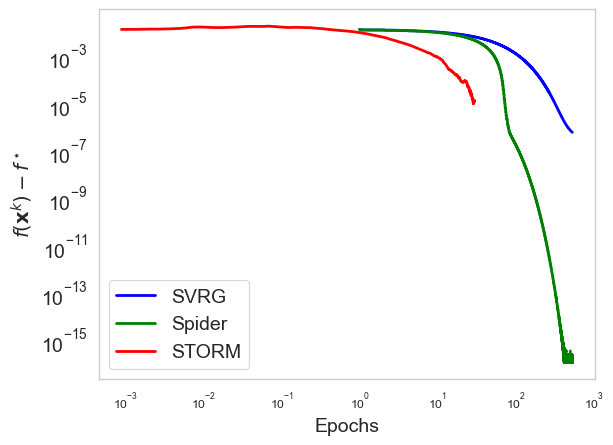

In [18]:
np.random.seed(0)
plot_epochs([SVRG, Spider, Storm], f, x_zero, 50000,
            x_axis="epochs")


__(g)__ (2 points) In the above plot, the number of epochs is defined as the number of individual sample gradient evaluations divided by the number of data samples $n$. Although SVRG, Spider, and STORM each perform 50,000 updates, their curves cover different ranges on the horizontal axis. Explain why.


The difference in epoch counts between the methods is due to how often they compute the full gradient:

* STORM never computes a full gradient: each update performs exactly 2 component-gradient evaluations (plus 1 at initialization). Over 50k updates this amounts to around 10^5 evaluations. So ~30 epochs, and the first plotted point sits at $3/n \approx 10^{-3}$ epochs.

* SVRG and Spider perform 2 component-gradient evaluations per update *and* recompute the full gradient $\nabla f$ every $q = 100$ iterations, which alone costs $n$ evaluations.
The first update k=0 triggers a gradient step, so their curves start at $\approx 1$ epoch, and over $50{,}000$ updates the 500 snapshots account for $\approx 500$ epochs (plus $\approx 30$ epochs of component evaluations), for a total of $\approx 530$ epochs.

Hence equal numbers of updates produce very different epoch counts: SVRG and Spider periodically pay the price of a full data pass, while STORM relies purely on recursive momentum and therefore covers far fewer epochs for the same number of iterations.

__(h)__ (5 points) **Uniform and importance sampling.**

The SGD method studied so far uses **uniform sampling (SGD-US)**: for a finite-sum objective $f=\frac{1}{n}\sum_{i=1}^n f_i$, it selects every component with equal probability. However, the components can have very different gradient Lipschitz constants $L_i$. Sampling components with larger $L_i$ more often can accelerate convergence. **SGD with importance sampling (SGD-IS)** implements this idea by choosing each component with probability proportional to $L_i$ and reweighting its gradient to keep the estimate unbiased. For background, see [Gower et al. (2019)](https://arxiv.org/pdf/1901.09401) and [Zhao and Zhang (2015)](https://proceedings.mlr.press/v37/zhaoa15.pdf).

Both SGD-US and SGD-IS are special cases of the general **SGD with non-uniform sampling (SGD-NS)** scheme, which allows arbitrary positive sampling probabilities, including uniform probabilities.

SGD-NS is:

Initialize $\mathbf{x}^0$, a step size $\gamma>0$, and probabilities $p_i>0$ summing to one. For $k=0,1,\ldots$:

$$
\begin{cases}
\text{Pick } i_k\in\{1,\ldots,n\}\text{ with probability }p_{i_k},\\
\mathbf{g}^k = \dfrac{\nabla f_{i_k}(\mathbf{x}^k)}{n p_{i_k}},\\
\mathbf{x}^{k+1} = \mathbf{x}^k - \gamma\mathbf{g}^k.
\end{cases}
$$

Then SGD-US and SGD-IS use the following choices of sampling probabilities and step sizes in this implementation:

| Method | Sampling probabilities | Step size |
|---|---|---|
| SGD-US | $p_i=1/n$ | $\gamma=1/\max_i L_i$ |
| SGD-IS | $p_i=L_i/\sum_j L_j$ | $\gamma=1/(\frac{1}{n}\sum_i L_i)$ |

<small>Here we use constant learning rates in both SGD-US and SGD-IS, rather than the diminishing learning rates commonly used in the standard theoretical analysis of SGD. This is a problem-specific choice intended to simplify the implementation, rather than a general recommendation for SGD.</small>

For this comparison, the helper supplies a separate test objective, passed to each algorithm as `f`, with the following interface:

- `f.n`: the number of component functions $f_i$.
- `f.i_grad(i, x)`: the gradient $\nabla f_i(x)$ of component `i` at `x`.
- `f[i].L`: the Lipschitz constant $L_i$ of the gradient $\nabla f_i$.

To sample a component index according to the probabilities specified above, use `np.random.choice(f.n, p=p)`, where `p` is a list or one-dimensional array containing one probability for each component, with entries summing to one. The call returns index `i` with probability `p[i]`.

Please implement SGD-US and SGD-IS by completing the initialization and update functions in the following cells, then run the final cell to compare their convergence.

In [19]:
from lib.quadratic_sampling import make_quadratic_problem, plot_sampling

f_quadratic, x_quadratic = make_quadratic_problem()

In [20]:
@dataclass
class SGD_US_state(OptState):
    x_k: Vector
    gamma: float

In [21]:
def SGD_US_update(f, state):
    x_k, gamma = state
    i_k = np.random.randint(f.n)
    # grad f_i / (n * 1/n) 
    g_k = f.i_grad(i_k, x_k)
    return SGD_US_state(x_k=x_k - gamma * g_k, gamma=gamma)


def SGD_US_initialize(f, x_zero):
    gamma = 1.0 / f.L_max
    return SGD_US_state(x_k=x_zero, gamma=gamma)

In [22]:
SGD_US = OptAlgorithm(name="SGD-US", init_state=SGD_US_initialize, state_update=SGD_US_update)

In [23]:
@dataclass
class SGD_IS_state(OptState):
    x_k: Vector
    p: Vector
    gamma: float

In [24]:
def SGD_IS_update(f, state):
    x_k, p, gamma = state
    i_k = np.random.choice(f.n, p=p)
    g_k = f.i_grad(i_k, x_k) / (f.n * p[i_k])  
    return SGD_IS_state(x_k=x_k - gamma * g_k, p=p, gamma=gamma)


def SGD_IS_initialize(f, x_zero):
    L = np.array([f[i].L for i in range(f.n)]) # Lipschitz constants for each component
    p = L / L.sum() # vector of probabilities
    gamma = 1.0 / L.mean()
    return SGD_IS_state(x_k=x_zero, p=p, gamma=gamma)

In [25]:
SGD_IS = OptAlgorithm(name="SGD-IS", init_state=SGD_IS_initialize, state_update=SGD_IS_update)

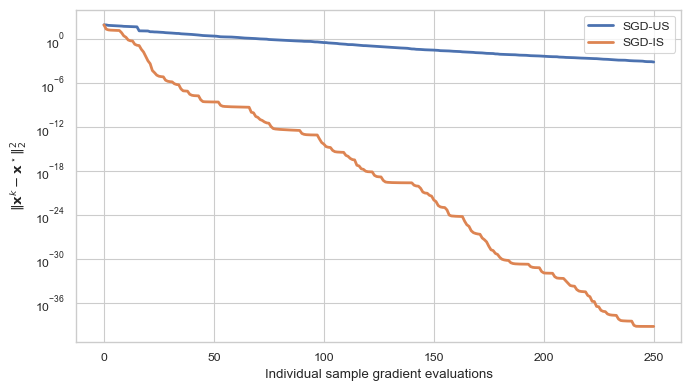

In [26]:
plot_sampling([SGD_US, SGD_IS], f_quadratic, x_quadratic)

Linear convergence !